<a href="https://colab.research.google.com/github/2025cishaunaquindsouzab-sketch/Dav-Lab-Programs-4NI25CI100/blob/main/Experential_Learning_4NI25CI100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DAES Experiential Learning Assignment (20 Marks)
## IPL Cricket Data Analysis (2008–2020)

**Student Name:** Shaun Aquin Dsouza
**USN:** 4NI25CI100  
**Class / Section:**AIML-B
**Subject:** Data Analytics & Exploration Series (DAES)

### Project objective
Use real-world Indian Premier League (IPL) match and ball-by-ball data to clean, explore, visualize and interpret cricket performance patterns.

**Dataset:** IPL Complete Dataset (2008–2020), containing `matches.csv` and `deliveries.csv`.  
**Tools:** Python, Pandas, NumPy, Matplotlib and Seaborn.

> Dataset coverage ends in 2020. Do not describe this historical dataset as current IPL data.


In [3]:
from google.colab import files
uploaded = files.upload()  # Select matches.csv and deliveries.csv


Saving deliveries.csv to deliveries.csv
Saving matches.csv to matches.csv


In [4]:
import zipfile
import os

# Path to the uploaded zip file
zip_path = 'archive (1) (1).zip'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("Successfully extracted all CSV files!")
    print("Current directory contents:", os.listdir('.'))
else:
    print(f"Could not find zip file at '{zip_path}'. Please verify the uploaded file name.")

Successfully extracted all CSV files!
Current directory contents: ['.config', 'matches.csv', 'archive (1) (1).zip', 'deliveries.csv', 'sample_data']


## 2. Import libraries and load data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Direct paths
match_path = 'matches.csv'
delivery_path = 'deliveries.csv'

if not os.path.exists(match_path) or not os.path.exists(delivery_path):
    raise FileNotFoundError("Please upload both matches.csv and deliveries.csv to the current directory.")

matches = pd.read_csv(match_path)
deliveries = pd.read_csv(delivery_path)

print("Matches shape:", matches.shape)
print("Deliveries shape:", deliveries.shape)
display(matches.head())
display(deliveries.head())

Matches shape: (1095, 20)
Deliveries shape: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


## 3. Understand columns, data types and quality

In [6]:
print("--- MATCHES INFO ---")
matches.info()
print("\n--- DELIVERIES INFO ---")
deliveries.info()

print("\nMatch columns:", list(matches.columns))
print("Delivery columns:", list(deliveries.columns))

print("\nMissing values in matches:")
display(matches.isna().sum().sort_values(ascending=False).to_frame("Missing"))

print("\nMissing values in deliveries:")
display(deliveries.isna().sum().sort_values(ascending=False).to_frame("Missing"))

print("\nDuplicate matches rows:", matches.duplicated().sum())
print("Duplicate deliveries rows:", deliveries.duplicated().sum())

--- MATCHES INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object

,Missing
method,1074
city,51
result_margin,19
player_of_match,5
winner,5
target_runs,3
target_overs,3
id,0
date,0
season,0



Missing values in deliveries:


,Missing
fielder,251566
dismissal_kind,247970
player_dismissed,247970
extras_type,246795
match_id,0
inning,0
batting_team,0
bowling_team,0
over,0
non_striker,0



Duplicate matches rows: 0
Duplicate deliveries rows: 0


## 4. Data cleaning and preprocessing

The code below handles common variations in IPL CSV schemas (for example, `id` versus `match_id`, `winner` versus `winner`, and `batsman` versus `batter`). It removes duplicate records, converts dates and numeric fields, and keeps missing values in optional fields where replacing them would be misleading.


In [7]:
# Work on copies
m = matches.copy()
d = deliveries.copy()

# Standardize column names to lowercase and strip whitespaces
m.columns = m.columns.str.strip().str.lower()
d.columns = d.columns.str.strip().str.lower()

# Standardize delivery columns
delivery_rename = {
    "batsman": "batter",
    "batsman_runs": "batter_runs",
    "batsman_run": "batter_runs"
}
d = d.rename(columns=delivery_rename)

# Standardize match ID column
if "id" in m.columns and "match_id" not in m.columns:
    m = m.rename(columns={"id": "match_id"})

if "match_id" not in d.columns:
    if "id" in d.columns:
        d = d.rename(columns={"id": "match_id"})
    else:
        raise ValueError("Could not find match identifier in deliveries columns: " + str(list(d.columns)))

# Remove duplicate rows
m = m.drop_duplicates().copy()
d = d.drop_duplicates().copy()

# Parse date column safely
if "date" in m.columns:
    m["date"] = pd.to_datetime(m["date"], errors="coerce")
    m["year"] = m["date"].dt.year

# Safely coerce columns to numeric type
numeric_m_cols = ["match_id"]
numeric_d_cols = ["match_id", "total_runs", "batter_runs", "extra_runs", "is_wicket"]

for col in numeric_m_cols:
    if col in m.columns:
        m[col] = pd.to_numeric(m[col], errors="coerce")

for col in numeric_d_cols:
    if col in d.columns:
        d[col] = pd.to_numeric(d[col], errors="coerce")

# Drop records with missing identifiers
d = d.dropna(subset=["match_id"])
m = m.dropna(subset=["match_id"])

print("Clean matches shape:", m.shape)
print("Clean deliveries shape:", d.shape)
print("Null match_id counts in deliveries:", d["match_id"].isna().sum())

Clean matches shape: (1095, 21)
Clean deliveries shape: (260920, 17)
Null match_id counts in deliveries: 0


## 5. Feature engineering and merged dataset

In [8]:
# Attach match information to each delivery
match_fields = [c for c in ["match_id", "season", "year", "city", "venue", "date",
                            "winner", "toss_winner", "toss_decision", "result",
                            "team1", "team2"] if c in m.columns]
ball = d.merge(m[match_fields].drop_duplicates("match_id"), on="match_id", how="left")

print("Merged ball-by-ball records:", ball.shape)
display(ball.head())

# Determine a season/year field robustly
season_col = "season" if "season" in ball.columns else ("year" if "year" in ball.columns else None)
if season_col:
    print("\nSeason range:", ball[season_col].dropna().min(), "to", ball[season_col].dropna().max())

Merged ball-by-ball records: (260920, 28)


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batter_runs,...,year,city,venue,date,winner,toss_winner,toss_decision,result,team1,team2
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,...,2008,Bangalore,M Chinnaswamy Stadium,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,field,runs,Royal Challengers Bangalore,Kolkata Knight Riders
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,...,2008,Bangalore,M Chinnaswamy Stadium,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,field,runs,Royal Challengers Bangalore,Kolkata Knight Riders
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,...,2008,Bangalore,M Chinnaswamy Stadium,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,field,runs,Royal Challengers Bangalore,Kolkata Knight Riders
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,...,2008,Bangalore,M Chinnaswamy Stadium,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,field,runs,Royal Challengers Bangalore,Kolkata Knight Riders
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,...,2008,Bangalore,M Chinnaswamy Stadium,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,field,runs,Royal Challengers Bangalore,Kolkata Knight Riders



Season range: 2007/08 to 2024


## 6. Exploratory Data Analysis (EDA) and visualizations

### 6.1 Matches played per season

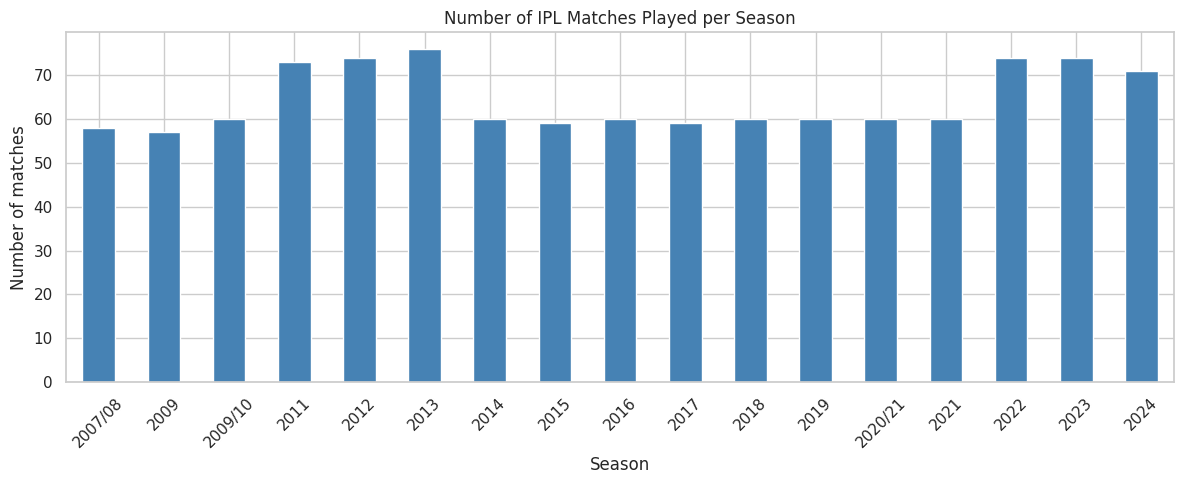

,Matches
season,
2007/08,58
2009,57
2009/10,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


In [9]:
if "season" in m.columns:
    season_counts = m.groupby("season")["match_id"].nunique().sort_index()
elif "year" in m.columns:
    season_counts = m.groupby("year")["match_id"].nunique().sort_index()
else:
    season_counts = pd.Series(dtype=int)

if not season_counts.empty:
    season_counts.plot(kind="bar", figsize=(12,5), color="steelblue")
    plt.title("Number of IPL Matches Played per Season")
    plt.xlabel("Season")
    plt.ylabel("Number of matches")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(season_counts.to_frame("Matches"))
else:
    print("No season data available.")

### 6.2 Most successful teams (titles / match wins)

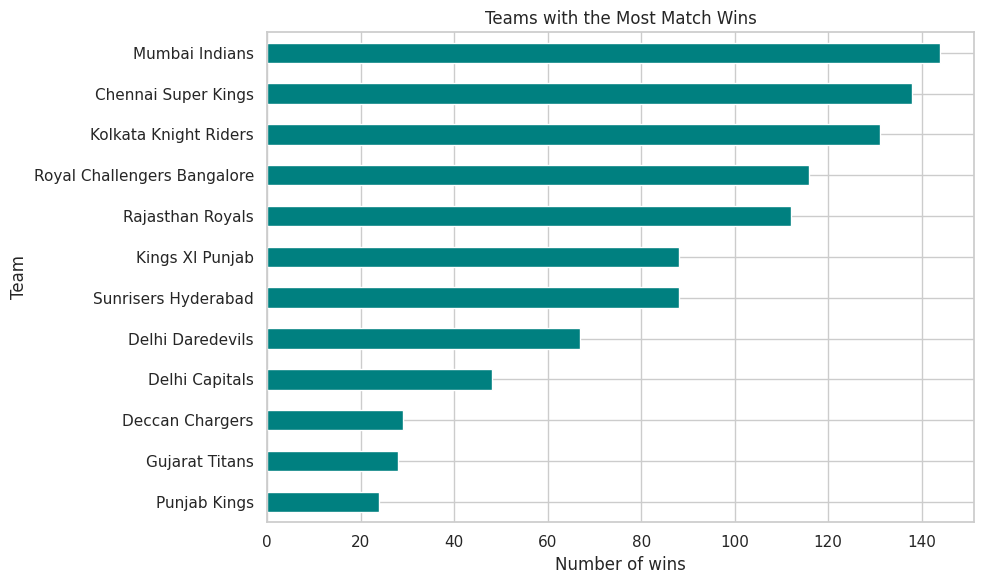

,Match_Wins
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bangalore,116
Rajasthan Royals,112
Sunrisers Hyderabad,88
Kings XI Punjab,88
Delhi Daredevils,67
Delhi Capitals,48


In [10]:
if "winner" in m.columns:
    wins = m["winner"].dropna().value_counts()
    if not wins.empty:
        wins.head(12).sort_values().plot(kind="barh", figsize=(10,6), color="teal")
        plt.title("Teams with the Most Match Wins")
        plt.xlabel("Number of wins")
        plt.ylabel("Team")
        plt.tight_layout()
        plt.show()
        display(wins.to_frame("Match_Wins"))
    else:
        print("No win data available.")
else:
    print("Winner column not found in matches dataset.")

### 6.3 Toss decision analysis

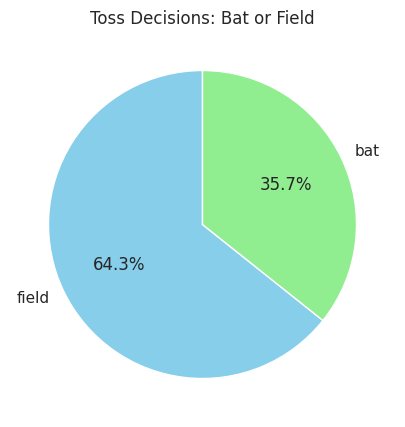

,Count
toss_decision,
field,704
bat,391


In [11]:
if {"toss_decision", "toss_winner"}.issubset(m.columns):
    toss_counts = m["toss_decision"].value_counts()
    if not toss_counts.empty:
        toss_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90, colors=["skyblue", "lightgreen"])
        plt.title("Toss Decisions: Bat or Field")
        plt.ylabel("")
        plt.show()
        display(toss_counts.to_frame("Count"))
    else:
        print("No toss decision data available.")

### 6.4 Does winning the toss relate to winning the match?

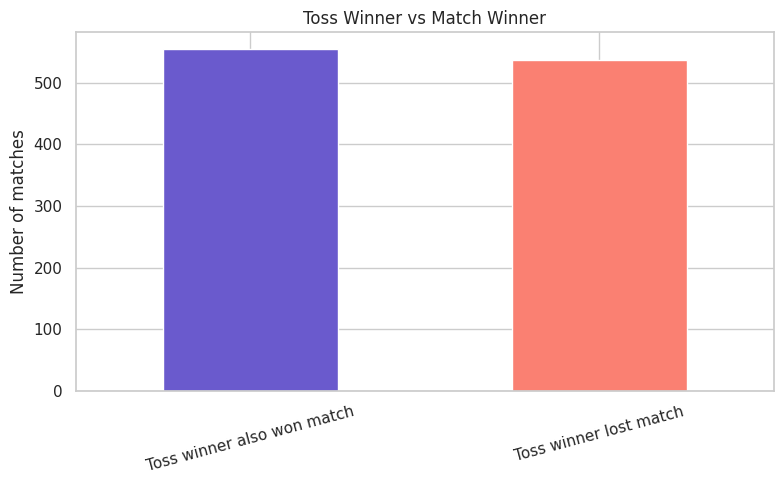

,Matches
Toss winner also won match,554
Toss winner lost match,536


In [12]:
if {"toss_winner", "winner"}.issubset(m.columns):
    valid = m.dropna(subset=["toss_winner", "winner"])
    if not valid.empty:
        toss_match_same = (valid["toss_winner"] == valid["winner"]).value_counts()
        toss_match_same.index = ["Toss winner also won match" if x else "Toss winner lost match" for x in toss_match_same.index]
        toss_match_same.plot(kind="bar", color=["slateblue","salmon"], figsize=(8,5))
        plt.title("Toss Winner vs Match Winner")
        plt.ylabel("Number of matches")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
        display(toss_match_same.to_frame("Matches"))
    else:
        print("No valid toss and winner data available.")

### 6.5 Top run scorers

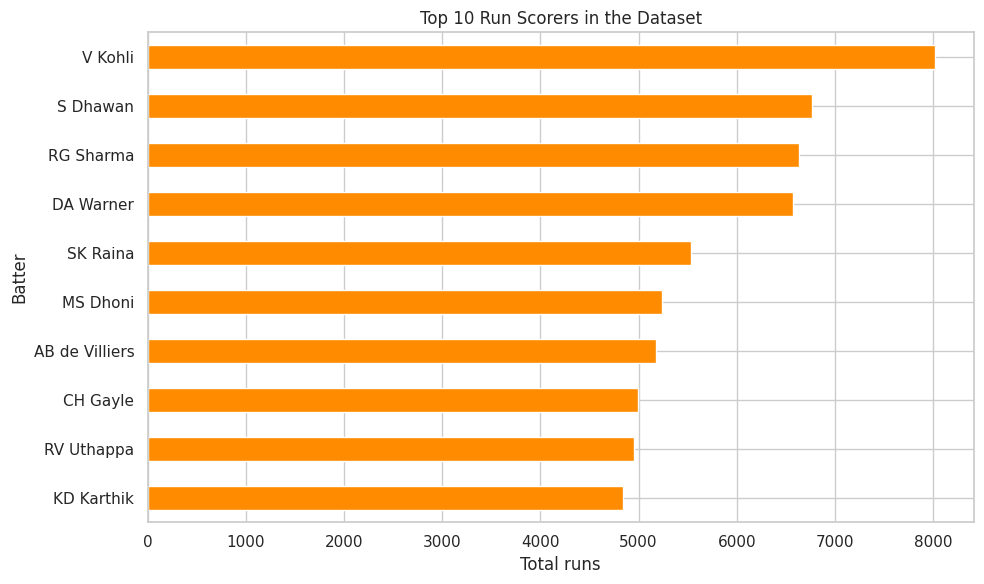

,Runs
batter,
V Kohli,8014
S Dhawan,6769
RG Sharma,6630
DA Warner,6567
SK Raina,5536
MS Dhoni,5243
AB de Villiers,5181
CH Gayle,4997
RV Uthappa,4954


In [13]:
if "batter" in ball.columns and "batter_runs" in ball.columns:
    batter_runs = ball.groupby("batter")["batter_runs"].sum().sort_values(ascending=False)
    if not batter_runs.empty:
        batter_runs.head(10).sort_values().plot(kind="barh", figsize=(10,6), color="darkorange")
        plt.title("Top 10 Run Scorers in the Dataset")
        plt.xlabel("Total runs")
        plt.ylabel("Batter")
        plt.tight_layout()
        plt.show()
        display(batter_runs.head(10).to_frame("Runs"))
    else:
        print("No batter runs data available.")
else:
    print("Batter or batter_runs column unavailable.")

### 6.6 Top wicket-taking bowlers

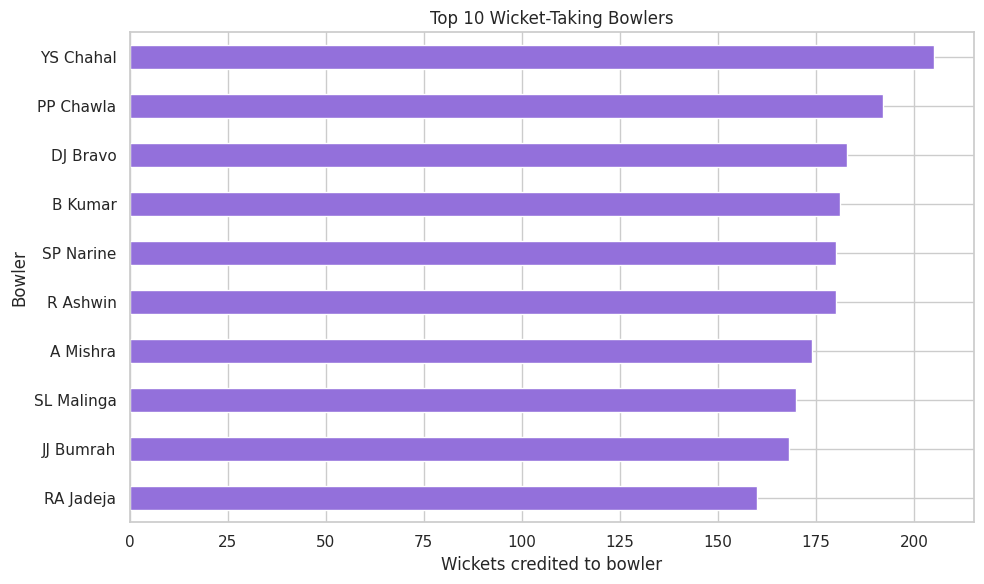

,Wickets
bowler,
YS Chahal,205
PP Chawla,192
DJ Bravo,183
B Kumar,181
R Ashwin,180
SP Narine,180
A Mishra,174
SL Malinga,170
JJ Bumrah,168


In [14]:
if "bowler" in ball.columns and "dismissal_kind" in ball.columns:
    non_bowler_dismissals = {"run out", "retired hurt", "obstructing the field", "retired out"}
    wickets = ball[ball["dismissal_kind"].notna() &
                   (~ball["dismissal_kind"].str.lower().isin(non_bowler_dismissals))]
    if not wickets.empty:
        bowler_wickets = wickets.groupby("bowler").size().sort_values(ascending=False)
        bowler_wickets.head(10).sort_values().plot(kind="barh", figsize=(10,6), color="mediumpurple")
        plt.title("Top 10 Wicket-Taking Bowlers")
        plt.xlabel("Wickets credited to bowler")
        plt.ylabel("Bowler")
        plt.tight_layout()
        plt.show()
        display(bowler_wickets.head(10).to_frame("Wickets"))
    else:
        print("No wickets registered for bowlers in this dataset.")
else:
    print("Bowler or dismissal_kind column unavailable.")

### 6.7 Runs scored by innings

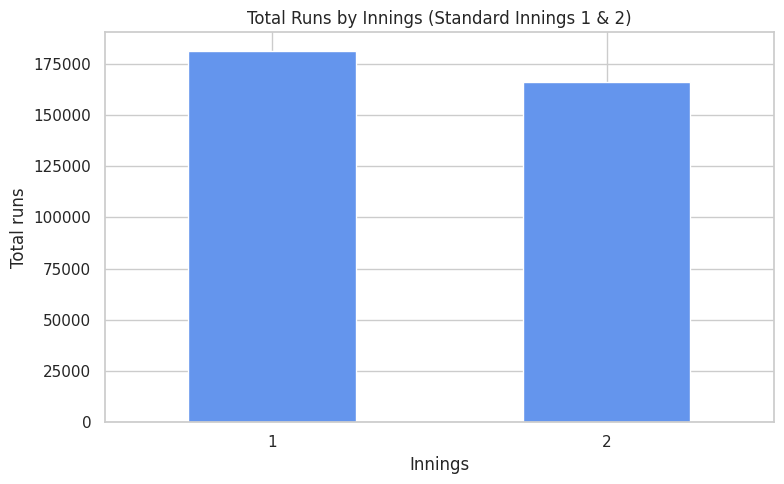

,Total_Runs
inning,
1,181274
2,166196


In [15]:
if {"inning", "total_runs"}.issubset(ball.columns):
    # Keep innings 1 and 2 as they are standard
    valid_innings = ball[ball["inning"].isin([1, 2])]
    innings_runs = valid_innings.groupby("inning")["total_runs"].sum()
    if not innings_runs.empty:
        innings_runs.plot(kind="bar", color="cornflowerblue", figsize=(8,5))
        plt.title("Total Runs by Innings (Standard Innings 1 & 2)")
        plt.xlabel("Innings")
        plt.ylabel("Total runs")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
        display(innings_runs.to_frame("Total_Runs"))
    else:
        print("No innings runs data available.")

### 6.8 Team scoring patterns

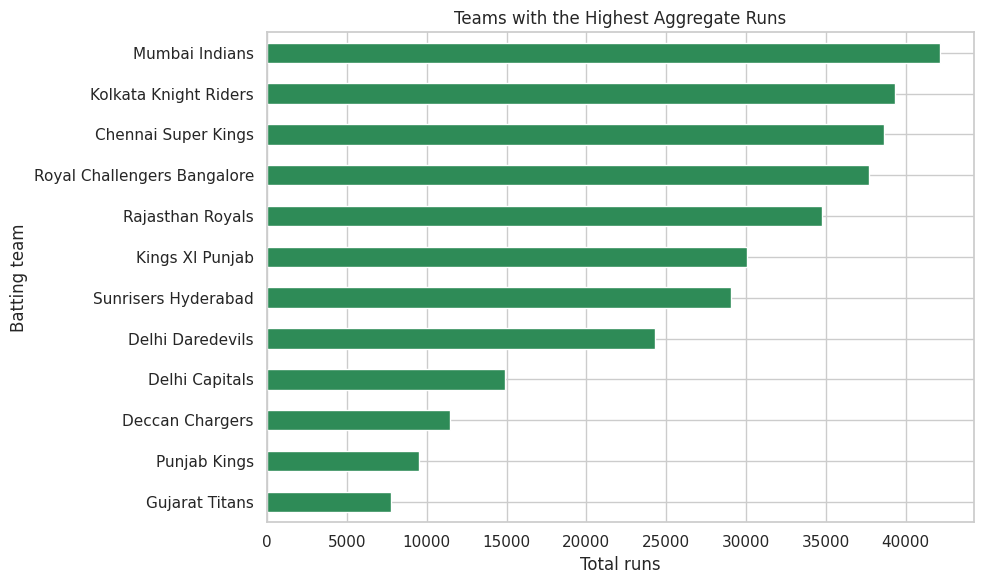

,Total_Runs
batting_team,
Mumbai Indians,42176
Kolkata Knight Riders,39331
Chennai Super Kings,38629
Royal Challengers Bangalore,37692
Rajasthan Royals,34747
Kings XI Punjab,30064
Sunrisers Hyderabad,29071
Delhi Daredevils,24296
Delhi Capitals,14900


In [16]:
if {"batting_team", "total_runs"}.issubset(ball.columns):
    team_runs = ball.groupby("batting_team")["total_runs"].sum().sort_values(ascending=False)
    if not team_runs.empty:
        team_runs.head(12).sort_values().plot(kind="barh", figsize=(10,6), color="seagreen")
        plt.title("Teams with the Highest Aggregate Runs")
        plt.xlabel("Total runs")
        plt.ylabel("Batting team")
        plt.tight_layout()
        plt.show()
        display(team_runs.head(12).to_frame("Total_Runs"))
    else:
        print("No team scoring data available.")

### 6.9 Player of the match awards

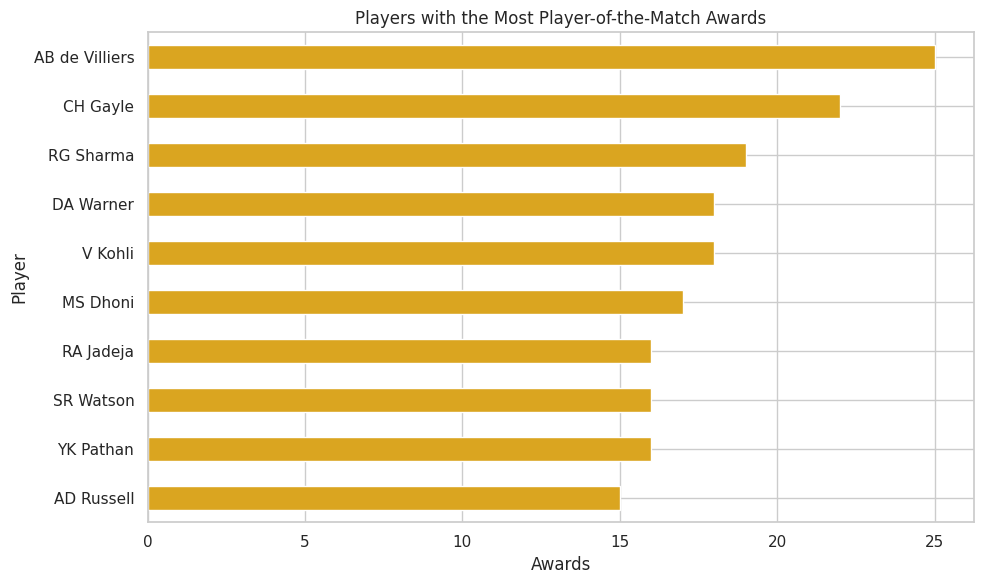

,Awards
player_of_match,
AB de Villiers,25
CH Gayle,22
RG Sharma,19
V Kohli,18
DA Warner,18
MS Dhoni,17
YK Pathan,16
RA Jadeja,16
SR Watson,16


In [17]:
if "player_of_match" in m.columns:
    awards = m["player_of_match"].dropna().value_counts()
    if not awards.empty:
        awards.head(10).sort_values().plot(kind="barh", figsize=(10,6), color="goldenrod")
        plt.title("Players with the Most Player-of-the-Match Awards")
        plt.xlabel("Awards")
        plt.ylabel("Player")
        plt.tight_layout()
        plt.show()
        display(awards.head(10).to_frame("Awards"))
    else:
        print("No awards data available.")

### 6.10 Venue-wise match count

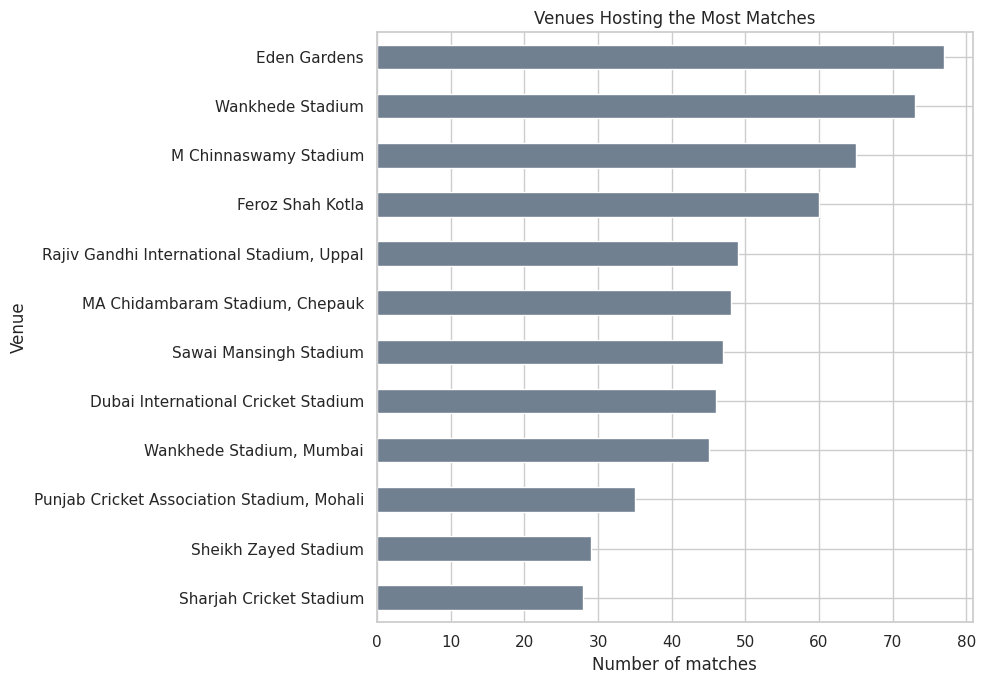

,Matches
venue,
Sharjah Cricket Stadium,28
Sheikh Zayed Stadium,29
"Punjab Cricket Association Stadium, Mohali",35
"Wankhede Stadium, Mumbai",45
Dubai International Cricket Stadium,46
Sawai Mansingh Stadium,47
"MA Chidambaram Stadium, Chepauk",48
"Rajiv Gandhi International Stadium, Uppal",49
Feroz Shah Kotla,60


In [18]:
if "venue" in m.columns:
    venue_counts = m["venue"].dropna().value_counts().head(12).sort_values()
    if not venue_counts.empty:
        venue_counts.plot(kind="barh", figsize=(10,7), color="slategray")
        plt.title("Venues Hosting the Most Matches")
        plt.xlabel("Number of matches")
        plt.ylabel("Venue")
        plt.tight_layout()
        plt.show()
        display(venue_counts.to_frame("Matches"))
    else:
        print("No venue data available.")

## 7. Key insights generated from your dataset

In [19]:
print("IPL DATA ANALYSIS - KEY FINDINGS")
print("=" * 48)

# 1. Team with the most match wins
if "winner" in m.columns and m["winner"].notna().any():
    winner_counts = m["winner"].value_counts()
    print(f"Team with most match wins: {winner_counts.idxmax()} - {int(winner_counts.max())} wins")

# 2. Most Player-of-the-Match awards
if "player_of_match" in m.columns and m["player_of_match"].notna().any():
    award_counts = m["player_of_match"].value_counts()
    print(f"Most Player-of-the-Match awards: {award_counts.idxmax()} - {int(award_counts.max())} awards")

# 3. Top run scorer
if "batter" in ball.columns and "batter_runs" in ball.columns:
    runs_grouped = ball.groupby("batter")["batter_runs"].sum()
    if not runs_grouped.empty:
        print(f"Top run scorer: {runs_grouped.idxmax()} ({runs_grouped.max():.0f} runs)")

# 4. Top wicket-taking bowler
if "bowler" in ball.columns and "dismissal_kind" in ball.columns:
    excluded_kinds = {"run out", "retired hurt", "obstructing the field", "retired out"}
    eligible_wickets = ball[ball["dismissal_kind"].notna() & (~ball["dismissal_kind"].str.lower().isin(excluded_kinds))]
    if not eligible_wickets.empty:
        bowler_counts = eligible_wickets.groupby("bowler").size()
        print(f"Top wicket-taking bowler: {bowler_counts.idxmax()} ({bowler_counts.max()} wickets)")

# 5. Season with the most matches
if "season" in m.columns:
    season_counts = m.groupby("season")["match_id"].nunique()
    if not season_counts.empty:
        print(f"Season with most matches: {season_counts.idxmax()} ({season_counts.max()} matches)")

IPL DATA ANALYSIS - KEY FINDINGS
Team with most match wins: Mumbai Indians - 144 wins
Most Player-of-the-Match awards: AB de Villiers - 25 awards
Top run scorer: V Kohli (8014 runs)
Top wicket-taking bowler: YS Chahal (205 wickets)
Season with most matches: 2013 (76 matches)
